In [1]:
from solver.utils.gmsh_function import *
from solver.utils.file_path import *
from solver.src.radiation_algorithm.radiation_algorithm import *
from nice_cube_gmsh import *

from solver.efield.efield1 import *
from solver.efield.efield2 import radiation_intensity_distribution_over_sphere_surface, display_rhcp_gain, display_lhcp_gain
from solver.efield.efield3 import antenna_directivity_pattern, display_rhcp_polar_pattern, display_lhcp_polar_pattern

from solver.utils.frequency_sweep import *

## This code create a 3D version of the nice Cubesat

In [2]:
name = "Nice_Cube"
path = setup_save_file_paths(name)

In [3]:
cm = 1e-2 # 1 cm
mm = 1e-3 # 1 mm

C = 10 * cm # Length of the cube's edge

initial_mesh_size = 35 * mm

space_btw_cubesat_and_solar_panel = 10 * mm # 1 cm = 10 mm

length_of_connection_between_cubesat_and_solar_panel = 1.5 * cm # 1.5 cm = 15 mm

In [4]:
# Coding the Nice CubeSat geometry
gmsh.initialize()

gmsh.model.add("CubeSat")

setup_performance_config()

create_nice_cube_geometry(C, space_btw_cubesat_and_solar_panel, length_of_connection_between_cubesat_and_solar_panel)
# create_nice_cube_geometry_v2(C, space_btw_cubesat_and_solar_panel, length_of_connection_between_cubesat_and_solar_panel)

generate_and_save_mesh(path, initial_mesh_size)

# gmsh.fltk.run()

gmsh.finalize()

[PERFORMANCE] Gmsh configured to utilize 16 threads.
Geometry file saved in data/gmsh_files/Nice_Cube.brep successfully
--- Starting Mesh Optimization (Dim: 2) ---
--- Optimization Complete ---
Mesh file saved in data/gmsh_files/Nice_Cube.msh successfully


In [5]:
feed_point = np.array([
    [C/2 + space_btw_cubesat_and_solar_panel, C/2 - length_of_connection_between_cubesat_and_solar_panel/2, 0],
    [-C/2 + length_of_connection_between_cubesat_and_solar_panel/2, C/2 + space_btw_cubesat_and_solar_panel, 0],
    [-C/2 - space_btw_cubesat_and_solar_panel, -C/2 + length_of_connection_between_cubesat_and_solar_panel/2, 0],
    [C/2 - length_of_connection_between_cubesat_and_solar_panel/2, -C/2 - space_btw_cubesat_and_solar_panel, 0]])

# phase for the 4 feed points of the nice cube, we set the phase to 0, 90, 180, and 270 degrees for the 4 feed points respectively
phase = np.array([0, 90, 180, 270]) * np.pi / 180

# voltage amplitude for the 4 feed points of the nice cube, we set the amplitude to 1 for certain feed points and -1 for others to create a specific radiation pattern
voltage_amplitude = [1, 1, -1, -1]

# Exitation units vector for the 4 feed points of the nice cube depending on how the solar panels are oriented
excitation_units_vector = ['x', 'y', 'x', 'y']

light_speed = 3e8
frequency = 440e6

wavelength = light_speed / frequency
print(f"wavelength = {wavelength} Meter")

wavelength = 0.6818181818181818 Meter


In [6]:
_ = radiation_algorithm(path, frequency, feed_point,
                        voltage_amplitude=voltage_amplitude, 
                        excitation_unit_vector=excitation_units_vector, 
                        gap_width=0.3*initial_mesh_size,
                        voltage_phase=phase,
                        show=True, save_image=False)

Number of points: 402
Number of triangles: 708
Number of edges: 1020
[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (1020x1020 edges).
Total input power P_in = 0.5*Re(V·I*) = 1.571401e-03 W
Port 0: P_in = 3.9236e-04 W  |  Q_in = 1.0521e-03 VAR  |  Z_in = 155.6047+417.2274j Ohm
Port 1: P_in = 3.9359e-04 W  |  Q_in = 1.0514e-03 VAR  |  Z_in = 156.1468+417.1096j Ohm
Port 2: P_in = 3.8999e-04 W  |  Q_in = 1.0688e-03 VAR  |  Z_in = 150.6511+412.8549j Ohm
Port 3: P_in = 3.9545e-04 W  |  Q_in = 1.0410e-03 VAR  |  Z_in = 159.4551+419.7440j Ohm


In [7]:
observationPoint = np.array([0, 0, -100])

calculate_electric_magnetic_field_at_point(path, observationPoint)


Frequency = 440000000.0 Hz
Wavelength lambda = 0.6812553499559301 m
The observation point is : [   0    0 -100]

e_field_total of Nice_Cube at the observation point [   0    0 -100] is :
 0.0026952 - 0.0032558i V/m
 0.0032873 + 0.0027108i V/m
-0.0000000 + 0.0000001i V/m

h_field_total of Nice_Cube at the observation point [   0    0 -100] is :
 0.0000087 + 0.0000072i A/m
-0.0000072 + 0.0000086i A/m
 0.0000000 - 0.0000000i A/m

Poynting vector is equal to : 
-4.0753948716954605e-13 W/m^2
1.039072502894763e-13 W/m^2
-4.779821415591381e-08 W/m^2

w = 4.779821415776414e-08 W/m^2

u = 0.0004779821415776414 W/unit solid angle


In [8]:
analyze_point_fields_polarization(path, observationPoint)


 ELECTROMAGNETIC ANALYSIS AT POINT: Nice_Cube

[Location]
  Cartesian (X, Y, Z) : (0.000, 0.000, -100.000) m
  Spherical (r, θ, φ) : (100.000 m, 180.00°, 0.00°)

[Cartesian E-Field (V/m)]
  Ex : +2.6952386e-03 -3.2558055e-03j
  Ey : +3.2873464e-03 +2.7107781e-03j
  Ez : -2.0579047e-08 +7.4765050e-08j

[Spherical E-Field (V/m)]
  E_theta : -2.6952386e-03 +3.2558055e-03j  (|E| = 4.22665e-03)
  E_phi   : +3.2873464e-03 +2.7107781e-03j  (|E| = 4.26086e-03)

[Circular Polarization]
  E_RHCP  : -3.8226311e-03 +4.6267071e-03j  (|E| = 6.00158e-03)
  E_LHCP  : +1.0988107e-05 -2.2302772e-05j  (|E| = 2.48627e-05)
  Axial Ratio : 1.0083 (0.07 dB)
  Detected Polarization Type: **CIRCULAR**

[Power Metrics]
  Poynting (Px, Py, Pz) : (-4.08e-13, 1.04e-13, -4.78e-08) W/m²
  Intensity (u)         : 4.77982e-04 W/sr




In [9]:
print("Calculating radiation intensity distribution over sphere surface...")
radiation_intensity_distribution_over_sphere_surface(path, save_image=False, save_gif=True)

Calculating radiation intensity distribution over sphere surface...
Hollow sphere loaded: 5150 points, 10296 triangles.

[Antenna Results]
  Total Radiated Power : 0.0015746640401504374 W
  Gain : 3.8066 (5.81 dBi)

[Power Budget]
  P_in  (0.5*Re(V·I*)) = 1.571401e-03 W
  P_rad (sphere integ.) = 1.574664e-03 W
  Raw efficiency       = 100.2077 %
  Port 0: Z_in = 155.6047+417.2274j Ω  |  R_in = 155.6047 Ω
  Port 1: Z_in = 156.1468+417.1096j Ω  |  R_in = 156.1468 Ω
  Port 2: Z_in = 150.6511+412.8549j Ω  |  R_in = 150.6511 Ω
  Port 3: Z_in = 159.4551+419.7440j Ω  |  R_in = 159.4551 Ω
  Total Efficiency     = 100.00 %
Data saved successfully to data/antennas_gain_power/Nice_Cube_gain_power.mat
Rendering 12 views at 3200x2800 px...
GIF saved: data/fig_image/radiation_pattern_Nice_Cube.gif (12 frames, 1044x1062 px, 500 ms/frame, 0.8 MB)


In [15]:
display_rhcp_gain(path, save_image=False, save_gif=True)


--- CALCULATING RHCP GAIN (RADIATION MODE) ---
Hollow sphere loaded: 5150 points, 10296 triangles.
Frequency = 4.40e+08 Hz | Wavelength lambda = 0.6813 m
Total Power : 0.0016 W
Max RHCP Gain : 5.8142 dBic

[Power Budget]
  P_in  (0.5*Re(V·I*)) = 1.571401e-03 W
  P_rad (sphere integ.) = 1.574664e-03 W
  Raw efficiency       = 100.2077 %
  Port 0: Z_in = 155.6047+417.2274j Ω  |  R_in = 155.6047 Ω
  Port 1: Z_in = 156.1468+417.1096j Ω  |  R_in = 156.1468 Ω
  Port 2: Z_in = 150.6511+412.8549j Ω  |  R_in = 150.6511 Ω
  Port 3: Z_in = 159.4551+419.7440j Ω  |  R_in = 159.4551 Ω
  Total Efficiency     = 100.00 %
Data saved successfully to data/antennas_gain_power/Nice_Cube_polar_rhcp_gain_power.mat
Rendering 12 views at 3200x2800 px...
GIF saved: data/fig_image/RHCP_pattern_Nice_Cube.gif (12 frames, 1100x1064 px, 500 ms/frame, 1.0 MB)


In [16]:
display_lhcp_gain(path, save_image=False, save_gif=True)


--- CALCULATING LHCP GAIN (RADIATION MODE) ---
Hollow sphere loaded: 5150 points, 10296 triangles.
Frequency = 4.40e+08 Hz | Wavelength lambda = 0.6813 m
Total Power : 0.0016 W
Max LHCP Gain : 4.4438 dBic

[Power Budget]
  P_in  (0.5*Re(V·I*)) = 1.571401e-03 W
  P_rad (sphere integ.) = 1.574664e-03 W
  Raw efficiency       = 100.2077 %
  Port 0: Z_in = 155.6047+417.2274j Ω  |  R_in = 155.6047 Ω
  Port 1: Z_in = 156.1468+417.1096j Ω  |  R_in = 156.1468 Ω
  Port 2: Z_in = 150.6511+412.8549j Ω  |  R_in = 150.6511 Ω
  Port 3: Z_in = 159.4551+419.7440j Ω  |  R_in = 159.4551 Ω
  Total Efficiency     = 100.00 %
Data saved successfully to data/antennas_gain_power/Nice_Cube_polar_lhcp_gain_power.mat
Rendering 12 views at 3200x2800 px...
GIF saved: data/fig_image/LHCP_pattern_Nice_Cube.gif (12 frames, 1068x1062 px, 500 ms/frame, 0.8 MB)


Generating antenna directivity pattern...
Data loaded from data/antennas_gain_power/Nice_Cube_gain_power.mat


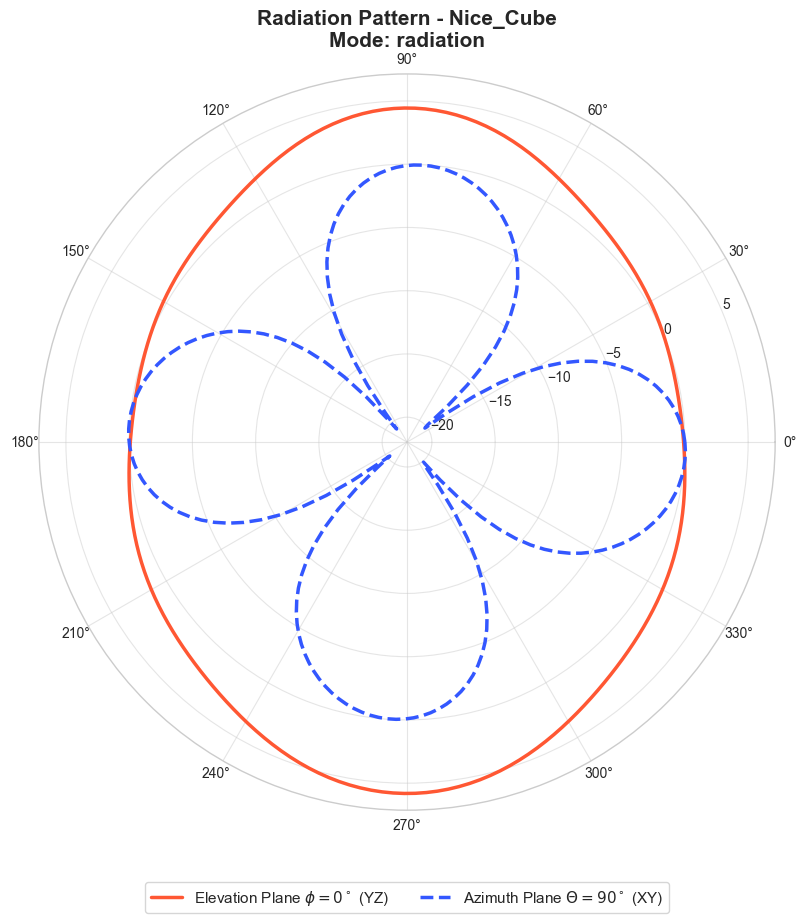

In [12]:
# Step 3: Generating the directivity pattern
print("Generating antenna directivity pattern...")
antenna_directivity_pattern(path, mode='radiation', save_image=False)

--- GENERATING RHCP POLAR PATTERN ---
Hollow sphere loaded: 5150 points, 10296 triangles.
Data loaded from data/antennas_gain_power/Nice_Cube_polar_rhcp_gain_power.mat


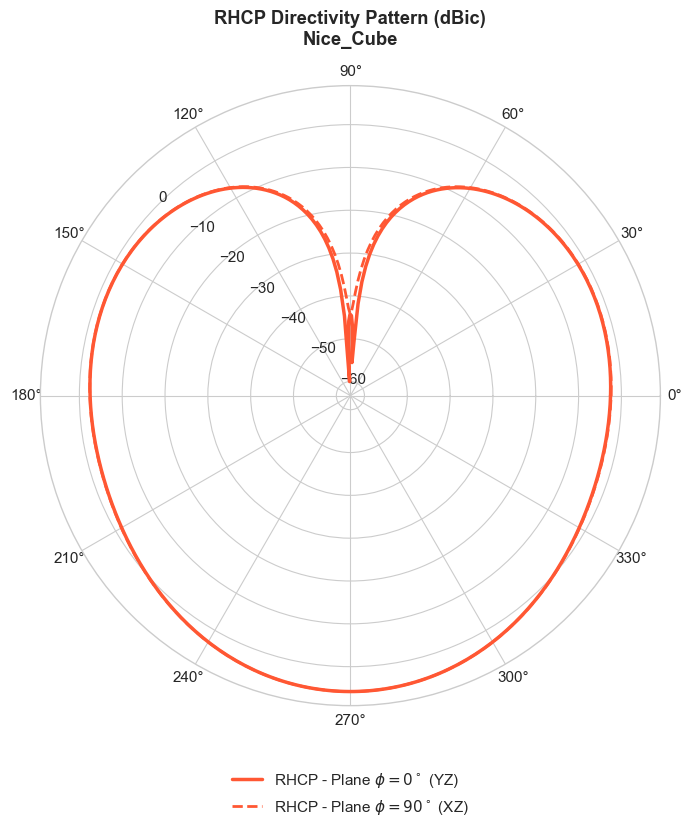

In [13]:
display_rhcp_polar_pattern(path, save_image=False)

--- GENERATING LHCP POLAR PATTERN ---
Hollow sphere loaded: 5150 points, 10296 triangles.
Data loaded from data/antennas_gain_power/Nice_Cube_polar_lhcp_gain_power.mat


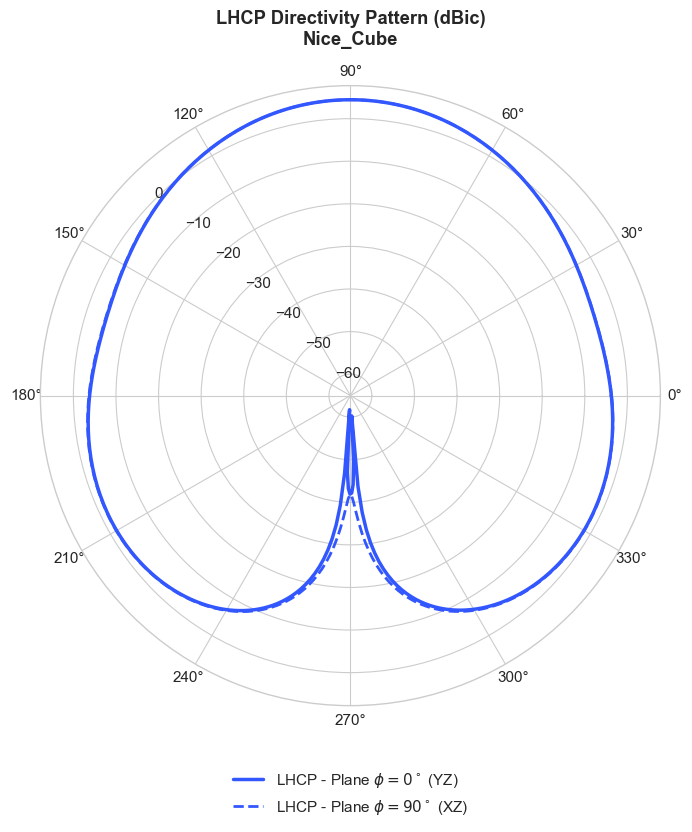

In [14]:
display_lhcp_polar_pattern(path, save_image=False)

freq_start = 400e6
freq_stop  = 500e6
frequency_sweep(path, freq_start, freq_stop,
                feed_point, excitation_unit_vector=excitation_units_vector, gap_width=0.1*initial_mesh_size, voltage_phase=phase,
                n_points=41, show=False)

plot_s_parameters(path, interpolation_threshold=0, save_pdf=True, save_folder="data/fig_image/")